# fMRI 인코더와 GPT-2를 연결한 NSD 캡션 생성

HCP 분류로 학습한 인코더를 GPT-2에 연결해 NSD β-map에서 캡션을 생성하는 실험이다. 인코더의 특징을 연속값 prefix 벡터로 바꾸고, 이를 언어모델 입력에 넣는다.

## 프로젝트 안에서의 역할

03 노트북의 분류 헤드를 제거하고 인코더 가중치를 불러온다. NSD β-map과 COCO 캡션으로 인코더·Bridge를 함께 학습하며 GPT-2 가중치는 고정한다. 학습에는 02 노트북 산출물이 아니라 별도로 제공된 NSD β-map을 사용한다.

## 실행 전 확인

- 03 노트북의 `fMRIEncoder` 정의, `drive_url`, `fmri_encoder_weights.pth`가 필요하다. 현재 파일만 실행하면 이 정의들이 자동으로 준비되지는 않는다.
- Drive에 NSD NPZ, `nsd_stim_info_saved.csv`, `coco_captions_saved.json`을 준비해야 한다.
- 마지막 추가 입력에는 02 노트북의 `NSD_01_data.npz`가 필요하다.
- 아래 수치와 문장은 기존 실행 기록이다. 문서 정리 과정에서 학습이나 평가를 다시 실행하지 않았다.


In [1]:
!pip install nilearn nibabel
!pip install antspyx
!pip install transformers evaluate rouge_score h5py


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 73.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.4/22.4 MB 35.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 12.6 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.3 MB/s eta 0:00:00
  Created wheel for rouge_score: filename=rouge_score-0.1.2-py3-none-any.whl size=24934 sha256=41ef39ddb0b2ff9dfbf3ca9807a7fb7c26ca1e2bde9ea34bf9d8114e7cb46715
  Stored in directory: /root/.cache/pip/wheels/85/9d/af/01feefbe7d55ef5468796f0c68225b6788e85d9d0a281e7a70
Successfully built rouge_score


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from pathlib import Path
import importlib.util
import nibabel as nib
from nilearn import image, plotting
from nilearn import datasets
from nilearn.maskers import NiftiMasker
from nilearn.glm.first_level import (
        FirstLevelModel,
        make_first_level_design_matrix,
    )
from nilearn.masking import apply_mask
from sklearn.model_selection import train_test_split
from scipy.spatial.transform import Rotation
import ants
import random
import json

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, TensorDataset, random_split
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, confusion_matrix
from sklearn.manifold import TSNE
from transformers import AutoTokenizer, AutoModelForCausalLM
import evaluate
import h5py
import nltk
from nltk.translate.bleu_score import sentence_bleu, SmoothingFunction
from nltk.translate.meteor_score import meteor_score
from rouge_score import rouge_scorer


## 1. 입력 데이터와 학습 구성

제공 NPZ의 `betas_int16`을 float32로 바꾸고 `scale`로 나누어 β 값을 복원한다. 각 벡터는 길이 100,000으로 pooling한다. `coco_ids`를 통해 캡션 사전과 연결하고 이미지마다 임의의 캡션 하나를 선택한다.

캡션 선택은 데이터셋을 만들 때 한 번 수행한다. 학습 중 매 epoch마다 새 캡션을 고르는 구조는 아니다. 텍스트는 최대 32토큰으로 자르고 패딩한다.

| 항목 | 실행 기록 |
|---|---|
| 읽은 NPZ 파일 | 10개 |
| 전체 표본 | 7,500 |
| Train / validation / test | 6,000 / 750 / 750 |
| 분할 방식 | `random_split`, 표본 단위 |
| Batch size | 64 |
| 언어모델 | GPT-2 |

동일 이미지의 반복 측정을 묶는 group split은 적용하지 않았다. 무작위 캡션 선택과 분할의 seed도 이 파일에서 고정하지 않으므로 재실행 결과가 달라질 수 있다.


## 2. 모델 구조와 학습 방식

```text
NSD β-map (100,000)
 → HCP 사전학습 인코더
 → 특징 벡터 (768)
 → Linear + Dropout
 → brain-prefix 벡터 3개 (각 768차원)
 → GPT-2
 → 캡션 생성
```

여기서 brain token은 어휘 사전에 추가한 정수 토큰이 아니라 **GPT-2 입력 임베딩 공간에 직접 전달하는 연속값 벡터**다. Bridge는 `768 → 3 × 768` 선형 투영과 dropout 0.3으로 구성된다. 클래스 기본 인자는 4개 토큰이지만 실제 모델은 `num_tokens=3`으로 생성한다.

| 모듈 | 학습 여부 |
|---|---|
| HCP 인코더 | NSD에서 fine-tuning |
| Bridge | 학습 |
| GPT-2 가중치 | 동결 |

### 학습과 생성의 차이

학습 시에는 `[brain-prefix, 정답 캡션 임베딩]`을 연결하고 causal language modeling loss를 계산한다. prefix 위치는 loss에서 제외한다. 캡션의 패딩 위치는 별도로 `-100` 처리하지 않는 현재 코드를 유지했다.

생성 시에는 정답 캡션 없이 prefix만 넣는다. 최대 30개 새 토큰, beam 수 3, sampling 없이 문장을 생성한다. 따라서 학습 loss 감소와 실제 생성 문장의 자극 일치 여부는 함께 살펴봐야 한다.

### 설정 변경 과정

초기에는 256차원 특징과 4~8개 prefix를 시도했다. 이후 특징을 768차원으로 늘리고 prefix를 3개로 조정했다. 최종 구성의 학습·생성 결과는 아래에 남겼으며, 이전 구성별 정량 비교표는 보관되어 있지 않다.

### 학습 기록

Adam, learning rate `1e-4`, 25 epochs로 인코더와 Bridge를 학습했다.

| Epoch | Train loss | Validation loss |
|---|---|---|
| 5 | 1.4722 | 1.4121 |
| 10 | 1.4230 | 1.3438 |
| 15 | 1.3944 | 1.3147 |
| 20 | 1.3721 | 1.3091 |
| 25 | 1.3495 | 1.2887 |

아래 셀은 데이터셋·모델 정의 → GPT-2와 인코더 로딩 → 학습 → 캡션 생성 평가 순서로 구성된다.


In [7]:


max_file = 10

class NSDCaptionDataset(Dataset):
    def __init__(self, tokenizer, max_len=32):
        self.df = pd.read_csv(f"{drive_url}/nsd_stim_info_saved.csv")
        with open(f"{drive_url}/coco_captions_saved.json", 'r') as f:
            self.captions_dict = json.load(f)

        self.tokenizer = tokenizer
        self.max_len = max_len
        self.data = []

        adaptive_pool = nn.AdaptiveAvgPool1d(100000)

        for idx, nsd_file in enumerate(os.listdir(f"{drive_url}/NSD_data")[:max_file]):
            data = np.load(f"{drive_url}/NSD_data/{nsd_file}", allow_pickle=True)
            print(f"{idx+1}st DataSet Columns:", data.files)

            compressed_list = []

            betas = data['betas_int16'].astype(np.float32) / data['scale']
            for beta in betas:
                tensor_data = torch.FloatTensor(beta).unsqueeze(0).unsqueeze(0)
                pooled_data = adaptive_pool(tensor_data)
                compressed_list.append(pooled_data.squeeze().numpy())

            coco_ids = data['coco_ids']

            for i in range(len(betas)):
                coco_id = str(coco_ids[i])

                if coco_id in self.captions_dict:

                    target_caption = random.choice(self.captions_dict[coco_id])
                    self.data.append((compressed_list[i], target_caption))

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        fmri, caption = self.data[idx]

        tokens = self.tokenizer(caption, max_length=self.max_len, padding='max_length', truncation=True, return_tensors="pt")

        return torch.tensor(fmri, dtype=torch.float32), tokens.input_ids.squeeze(0), tokens.attention_mask.squeeze(0), caption

class BrainToTextModel(nn.Module):
    def __init__(self, encoder, llm_model, num_tokens=4):
        super(BrainToTextModel, self).__init__()
        self.encoder = encoder
        self.llm = llm_model
        self.llm_dim = self.llm.config.hidden_size
        self.num_tokens = num_tokens

        self.bridge = nn.Sequential(
            nn.Linear(768, self.num_tokens * self.llm_dim),
            nn.Dropout(0.3)
        )

        for param in self.llm.parameters():
            param.requires_grad = False

    def forward(self, fmri, input_ids, attention_mask):

        fmri_features = self.encoder(fmri)

        prompt_embeds = self.bridge(fmri_features).view(-1, self.num_tokens, self.llm_dim)

        text_embeds = self.llm.transformer.wte(input_ids)

        inputs_embeds = torch.cat([prompt_embeds, text_embeds], dim=1)

        prompt_mask = torch.ones(input_ids.shape[0], self.num_tokens).to(device)
        extended_mask = torch.cat([prompt_mask, attention_mask], dim=1)

        ignore_index = torch.full((input_ids.shape[0], self.num_tokens), -100).to(device)

        labels = torch.cat([ignore_index, input_ids], dim=1)

        outputs = self.llm(inputs_embeds=inputs_embeds, attention_mask=extended_mask, labels=labels)
        return outputs.loss

    @torch.no_grad()
    def generate(self, fmri, tokenizer, max_new_tokens=30):
        fmri_features = self.encoder(fmri)
        prompt_embeds = self.bridge(fmri_features)

        if prompt_embeds.dim() == 2:
            prompt_embeds = prompt_embeds.view(prompt_embeds.shape[0], self.num_tokens, -1)

        generated_ids = self.llm.generate(
            inputs_embeds=prompt_embeds,
            max_new_tokens=max_new_tokens,
            pad_token_id=tokenizer.pad_token_id,
            eos_token_id=tokenizer.eos_token_id,
            do_sample=False,
            num_beams=3
        )

        generated_texts = tokenizer.batch_decode(generated_ids, skip_special_tokens=True)
        return generated_texts


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2LMHeadModel LOAD REPORT from: gpt2
Key                  | Status     |  | 
---------------------+------------+--+-
h.{0...11}.attn.bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
2st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
3st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
4st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
5st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
6st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices', 'subject', 'nsd_subject', 'session', 'trials_per_session', 'source']
7st DataSet Columns: ['betas_int16', 'scale', 'nsd_ids', 'coco_ids', 'roi_indices'

`loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch 5/25 | Train Loss: 1.4722 | Val Loss: 1.4121
Epoch 10/25 | Train Loss: 1.4230 | Val Loss: 1.3438
Epoch 15/25 | Train Loss: 1.3944 | Val Loss: 1.3147
Epoch 20/25 | Train Loss: 1.3721 | Val Loss: 1.3091
Epoch 25/25 | Train Loss: 1.3495 | Val Loss: 1.2887


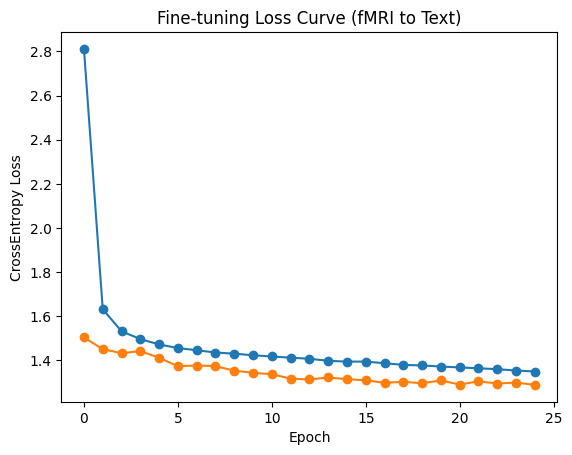

In [8]:

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_name = "gpt2"
tokenizer = AutoTokenizer.from_pretrained(model_name)
tokenizer.pad_token = tokenizer.eos_token
llm = AutoModelForCausalLM.from_pretrained(model_name).to(device)

dataset = NSDCaptionDataset(tokenizer)

train_size = int(0.8 * len(dataset))
val_size = int(0.1 * len(dataset))
test_size = len(dataset) - train_size - val_size
train_dataset, val_dataset, test_dataset = random_split(
    dataset, [train_size, val_size, test_size]
)
print(f"Total: {len(dataset)}")
print(f"Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)}")

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

encoder = fMRIEncoder(input_dim=100000, feature_dim=768)
encoder.load_state_dict(torch.load(f"{drive_url}/fmri_encoder_weights.pth", map_location=device))

model = BrainToTextModel(encoder, llm, num_tokens=3).to(device)

optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-4)

epochs = 25
train_loss_history = []
val_loss_history = []

for epoch in range(epochs):

    model.train()
    train_epoch_loss = 0

    for fmri, input_ids, mask, _ in train_loader:
        fmri, input_ids, mask = fmri.to(device), input_ids.to(device), mask.to(device)

        optimizer.zero_grad()
        loss = model(fmri, input_ids, mask)
        loss.backward()
        optimizer.step()

        train_epoch_loss += loss.item()

    avg_train_loss = train_epoch_loss / len(train_loader)
    train_loss_history.append(avg_train_loss)

    model.eval()
    val_epoch_loss = 0

    with torch.no_grad():
        for fmri, input_ids, mask, _ in val_loader:
            fmri, input_ids, mask = fmri.to(device), input_ids.to(device), mask.to(device)
            loss = model(fmri, input_ids, mask)
            val_epoch_loss += loss.item()

    avg_val_loss = val_epoch_loss / len(val_loader)
    val_loss_history.append(avg_val_loss)
    if (epoch+1) % 5 == 0:
        print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

plt.plot(train_loss_history, label='Train Loss', marker='o')
plt.plot(val_loss_history, label='Validation Loss', marker='o')
plt.title("Fine-tuning Loss Curve (fMRI to Text)")
plt.xlabel("Epoch")
plt.ylabel("CrossEntropy Loss")
plt.show()


In [9]:

nltk.download('wordnet')
nltk.download('punkt')
nltk.download('omw-1.4')
nltk.download('punkt_tab')

def evaluate_and_show_samples(model, test_loader, tokenizer, num_samples=10):
    model.eval()

    all_bleu1, all_bleu2, all_bleu3, all_bleu4 = [], [], [], []
    all_meteor, all_rougeL = [], []

    scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
    smoothie = SmoothingFunction().method4

    samples_shown = 0

    print("Visualization of 10 samples")

    for batch_idx, (fmri, input_ids, mask, target_captions) in enumerate(test_loader):
        fmri = fmri.to(device)

        with torch.no_grad():
            preds = model.generate(fmri, tokenizer)

        for i in range(len(preds)):
            pred_text = preds[i].strip()
            refs_text = target_captions[i]

            pred_tokens = nltk.word_tokenize(pred_text.lower())
            refs_tokens = [nltk.word_tokenize(ref.lower()) for ref in refs_text]

            b1 = sentence_bleu(refs_tokens, pred_tokens, weights=(1, 0, 0, 0), smoothing_function=smoothie)
            b2 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothie)
            b3 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoothie)
            b4 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)

            met = meteor_score(refs_tokens, pred_tokens)

            rouge_scores = [scorer.score(ref, pred_text)['rougeL'].fmeasure for ref in refs_text]
            best_rouge = max(rouge_scores)

            all_bleu1.append(b1); all_bleu2.append(b2); all_bleu3.append(b3); all_bleu4.append(b4)
            all_meteor.append(met); all_rougeL.append(best_rouge)

            if samples_shown < num_samples:
                print(f"[Sample {samples_shown+1}]")
                print(f"• Image/fMRI ID : Batch {batch_idx}, Item {i}")
                print(f"• Reference: {refs_text}")
                print(f"• Decoded Pred: {pred_text}")
                print(f"• Metrics     : BLEU-4: {b4:.4f} | METEOR: {met:.4f} | ROUGE-L: {best_rouge:.4f}")
                print("-" * 50)

                samples_shown += 1

    print(f"BLEU-1: {np.mean(all_bleu1):.4f}")
    print(f"BLEU-2: {np.mean(all_bleu2):.4f}")
    print(f"BLEU-3: {np.mean(all_bleu3):.4f}")
    print(f"BLEU-4: {np.mean(all_bleu4):.4f}")
    print(f"METEOR: {np.mean(all_meteor):.4f}")
    print(f"ROUGE-L: {np.mean(all_rougeL):.4f}")

evaluate_and_show_samples(model, test_loader, tokenizer, num_samples=10)


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


Visualization of 10 samples


The attention mask is not set and cannot be inferred from input because pad token is same as eos token. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.


[Sample 1]
• Image/fMRI ID : Batch 0, Item 0
• Reference: several red ripe apples in two large wooden boxes
• Decoded Pred: A large bowl of rice and a large bowl of noodles.
• Metrics     : BLEU-4: 0.0200 | METEOR: 0.2381 | ROUGE-L: 0.1667
--------------------------------------------------
[Sample 2]
• Image/fMRI ID : Batch 0, Item 1
• Reference: A woman sitting at a table with plates of food.
• Decoded Pred: A woman is sitting on a bench with her hands on her hips.
• Metrics     : BLEU-4: 0.0209 | METEOR: 0.2174 | ROUGE-L: 0.1429
--------------------------------------------------
[Sample 3]
• Image/fMRI ID : Batch 0, Item 2
• Reference: Room with wood covered wall and floor with two beds.
• Decoded Pred: A large room with a bed and a desk.
• Metrics     : BLEU-4: 0.0279 | METEOR: 0.2632 | ROUGE-L: 0.2000
--------------------------------------------------
[Sample 4]
• Image/fMRI ID : Batch 0, Item 3
• Reference: a green field that has a man with a kite
• Decoded Pred: A man standing on

## 3. 생성 결과 읽기

기존 출력에는 test 데이터의 첫 10개 예시와 전체 평균 점수가 남아 있다. 일부 문장에는 정답과 겹치는 개념이 나타나지만, 다른 대상을 생성하거나 비슷한 표현을 반복하는 경우도 있다.

| 정답 캡션 요약 | 실제 생성 문장 | 관찰 |
|---|---|---|
| 침대 두 개가 있는 방 | A large room with a bed and a desk. | 방·침대는 겹치며 세부 내용은 다름 |
| 사과가 담긴 나무 상자 | A large bowl of rice and a large bowl of noodles. | 중심 대상 불일치 |
| 들판의 얼룩말 | A man is standing on a tree in the middle of the forest. | 자극과 무관한 내용 |

전체 예시는 위 실행 출력에서 볼 수 있다. 표시된 ID는 실제 COCO 이미지 ID가 아니라 batch/item 위치다. 평가에는 데이터셋 생성 시 고른 캡션 하나가 전달되며, 이미지별 5개 reference를 출력하는 구성은 아니다. CIDEr 계산도 포함되어 있지 않다.

### 저장된 점수에 관한 확인 사항

현재 `__getitem__`은 캡션 문자열 하나를 반환하고, 평가 루프는 `refs_text`를 순회해 reference를 만든다. 첨부된 코드 흐름대로라면 문자열의 각 문자를 순회하게 된다. 실행 환경에서 다른 데이터 구조를 사용했는지는 이 파일만으로 확인되지 않는다. **아래 보존된 점수를 대표 성능으로 인용하기 전에는 실제 reference 자료형을 확인해야 한다.** 이번 편집에서는 평가 코드와 점수를 수정하지 않았다.

### 생성 시 경고

기존 출력에는 PAD와 EOS가 같고 생성용 attention mask가 명시되지 않았다는 경고가 있다. 학습 시 마스크는 전달하지만 `generate`에서는 별도 마스크를 지정하지 않는 현재 구현을 그대로 보존했다.


In [16]:

ablation_data_zero = np.zeros((1, 100000))
ablation_data_random = np.random.rand(3, 100000)

ablation_data = np.vstack((ablation_data_zero, ablation_data_random))

with torch.no_grad():
    preds = model.generate(torch.FloatTensor(ablation_data).to(device), tokenizer)

model.eval()

for i in range(len(preds)):
    pred_text = preds[i].strip()

    pred_tokens = nltk.word_tokenize(pred_text.lower())

    print(f"• Decoded Pred: {pred_text}")


• Decoded Pred: A man walks up to a tree and sees a tree.
• Decoded Pred: A man walks up to a tree with his hands on a tree.
• Decoded Pred: A man walks up to a tree with his hands on a tree.
• Decoded Pred: A man walks up to a tree with his hands on a tree.


## 4. 입력 통제 실험: zero와 random 벡터

실제 β-map 대신 zero 벡터 하나와 random 벡터 세 개를 넣어 출력을 비교했다. 코드의 `np.random.rand`는 정규분포가 아니라 **[0, 1) 균등분포**다.

기존 결과에서는 zero 입력과 random 입력 모두 문장을 생성했고, random 입력들은 같은 문장을 출력했다. 이는 학습된 언어모델이 자연스러운 문장을 만든다는 사실과 입력의 정보를 충실하게 반영한다는 사실을 구분해서 볼 필요가 있음을 보여준다.

이 실험은 간단한 입력 진단이다. 실제 입력 대비 정량 점수나 동일 분포의 shuffled-input 비교는 수행하지 않았다.


In [17]:

data = np.load(f"{drive_url}/preprocessed data/NSD_preprocessed/NSD_01_data.npz", allow_pickle=True)

adaptive_pool = nn.AdaptiveAvgPool1d(100000)

compressed_list = []

for data_ in data['data']:
    tensor_data = torch.FloatTensor(data_).unsqueeze(0).unsqueeze(0)
    pooled_data = adaptive_pool(tensor_data)
    compressed_list.append(pooled_data.squeeze().numpy())

with open(f"{drive_url}/coco_captions_saved.json", 'r') as f:
    captions_dict = json.load(f)

with torch.no_grad():
    preds = model.generate(torch.FloatTensor(compressed_list).to(device), tokenizer)

model.eval()

scorer = rouge_scorer.RougeScorer(['rougeL'], use_stemmer=True)
smoothie = SmoothingFunction().method4

samples_shown = 0
num_samples = 10
smoothie = SmoothingFunction().method4
for i in range(len(preds)):
    pred_text = preds[i].strip()
    refs_text = random.choice(captions_dict[data['labels'][i]])

    pred_tokens = nltk.word_tokenize(pred_text.lower())
    refs_tokens = [nltk.word_tokenize(ref.lower()) for ref in refs_text]

    b1 = sentence_bleu(refs_tokens, pred_tokens, weights=(1, 0, 0, 0), smoothing_function=smoothie)
    b2 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.5, 0.5, 0, 0), smoothing_function=smoothie)
    b3 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.33, 0.33, 0.33, 0), smoothing_function=smoothie)
    b4 = sentence_bleu(refs_tokens, pred_tokens, weights=(0.25, 0.25, 0.25, 0.25), smoothing_function=smoothie)

    met = meteor_score(refs_tokens, pred_tokens)

    rouge_scores = [scorer.score(ref, pred_text)['rougeL'].fmeasure for ref in refs_text]
    best_rouge = max(rouge_scores)

    if samples_shown < num_samples:
        print(f"[Sample {samples_shown+1}]")
        print(f"• Image/fMRI ID : Item {i}")
        print(f"• Reference: {refs_text}")
        print(f"• Decoded Pred: {pred_text}")
        print(f"• Metrics     : BLEU-4: {b4:.4f} | METEOR: {met:.4f} | ROUGE-L: {best_rouge:.4f}")
        print("-" * 50)

        samples_shown += 1


/tmp/ipykernel_807/712379920.py:17: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  preds = model.generate(torch.FloatTensor(compressed_list).to(device), tokenizer)


[Sample 1]
• Image/fMRI ID : Item 0
• Reference: Skiers and snowboarders going down a run on a sunny day.
• Decoded Pred: A man standing on a beach with his head covered in sand.
• Metrics     : BLEU-4: 0.0223 | METEOR: 0.2273 | ROUGE-L: 0.1538
--------------------------------------------------
[Sample 2]
• Image/fMRI ID : Item 1
• Reference: A pizza on a plate with a fork and knife.
• Decoded Pred: A man is standing on a beach with his head covered in sand.
• Metrics     : BLEU-4: 0.0209 | METEOR: 0.2174 | ROUGE-L: 0.1429
--------------------------------------------------
[Sample 3]
• Image/fMRI ID : Item 2
• Reference: A large dog wearing an orange safety vest.
• Decoded Pred: A man standing on a beach with his hands on his head.
• Metrics     : BLEU-4: 0.0223 | METEOR: 0.2273 | ROUGE-L: 0.1538
--------------------------------------------------
[Sample 4]
• Image/fMRI ID : Item 3
• Reference: A cat rclining in a red leather easy chair
• Decoded Pred: A man standing on a beach with hi

## 5. 직접 전처리한 NSD 데이터의 추가 입력

02 노트북의 `NSD_01_data.npz`를 길이 100,000으로 맞춰 모델에 넣었다. 저장된 이미지 ID는 캡션 사전과 다시 연결해 예시를 표시했다.

기존 출력에서는 스키, 피자, 개, 고양이 등 서로 다른 자극에도 해변에 서 있는 사람을 묘사하는 문장이 반복되었다. 제공 데이터와 직접 전처리 데이터는 마스크·공간 정합·β 추정 및 값의 분포가 다를 수 있다. 입력 길이 통일만으로 두 데이터가 같은 특징 체계를 갖게 되는 것은 아니다.

이 결과는 별도 입력에 대한 탐색적 테스트이며, 앞의 held-out test와 구분한다. 여기에도 같은 reference 구성 방식이 사용되므로 표시된 텍스트 지표를 해석하기 전 자료형 확인이 필요하다.

## 정리

HCP 분류 인코더를 GPT-2 입력에 연결하고, NSD 데이터로 인코더와 Bridge를 학습하는 흐름을 구현했다. 학습 loss는 감소했으며 prefix만으로 문장을 생성할 수 있었다. 생성 문장에서는 일부 개념 중첩과 함께 대상 불일치·반복 출력도 관찰됐다.

현재 기록은 모델 연결과 동작을 보여주는 실험이다. 최종 결과를 종합할 때는 loss, 실제 생성 예시, 입력 통제 결과를 함께 제시하고, 저장된 캡션 점수는 reference 구조 확인 후 사용한다.
